# **Уровень 3 — Исследовательский (варианты 21–30, максимум 10 баллов)**

**Общая часть:** сформулировать гипотезу, провести эксперимент, сравнить Word2Vec с современными альтернативами (FastText, sentence-transformers / rubert-tiny2) и/или углублённо исследовать факторы, влияющие на визуализацию. Результаты должны быть воспроизводимы, а выводы — обоснованы.

**Вариант 22 — Статические и контекстные эмбеддинги**

Получить векторы для тех же токенов с помощью sentence-transformers, используя модель **cointegrated/rubert-tiny2**, и визуализировать их рядом с векторами Word2Vec. Объяснить, почему контекстные модели дают иную геометрию.

rubert-tiny2 — компактная русскоязычная BERT-модель с качественными векторными представлениями предложений размерности **312**.

Модель: [cointegrated/rubert-tiny2](https://huggingface.co/cointegrated/rubert-tiny2).


# Гипотеза

Поскольку модель Word2Vec обучается на содержимом заданного текста, её качество будет сильно зависеть от объёма и полноты этого текста. В отличие от неё, rubert-tiny2 — предобученная модель, не зависящая от заданного текста. Поскольку используемый сейчас текстовый корпус очень большой, значительной разницы между моделями быть не должно.


## Лемматизация

Лемматизация определена непосредственно в этом блокноте и выполняется на центральном процессоре. Мы приводим текст к нижнему регистру, извлекаем русские слова и выбираем первый вариант леммы, предложенный pymorphy3. Стоп-слова не удаляются, минимальная длина в три буквы на этом этапе не применяется. Анализатор используется повторно, а `lru_cache` позволяет не повторять анализ одних и тех же слов в течение сеанса.


In [18]:
import polars as pl
import re
import pymorphy3
from functools import lru_cache

# Используем только первые 10 000 отзывов.
df = pl.read_ndjson("texts/kinopoisk.jsonl", n_rows=10_000)
print("Количество выбранных отзывов:", f"{df.height:,}".replace(",", " "))
datos = df.select("content")

morph = pymorphy3.MorphAnalyzer()

@lru_cache(maxsize=100_000)
def obtener_lema(palabra):
    return morph.parse(palabra)[0].normal_form

def lematizar(texto):
    palabras = re.findall(r"[а-яё]+", texto.lower())
    return [obtener_lema(palabra) for palabra in palabras]

datos = datos.with_columns(
    pl.col("content")
    .fill_null("")
    .map_elements(lematizar, return_dtype=pl.List(pl.String))
    .alias("lemmas")
)

# Отображаем русские заголовки, сохраняя внутренние имена столбцов.
from html import escape
from IPython.display import HTML, display

vista = datos.select("content", "lemmas").head()
filas = "".join(
    "<tr><td>" + escape(texto[:180] + ("…" if len(texto) > 180 else ""))
    + "</td><td>" + escape(", ".join(lemas[:12]) + ("…" if len(lemas) > 12 else ""))
    + "</td></tr>"
    for texto, lemas in vista.iter_rows()
)
display(HTML(
    '<style>.ru-preview td,.ru-preview th {padding:8px; text-align:left; '
    'vertical-align:top; border:1px solid #999; max-width:480px;}</style>'
    f"<p>Первые {vista.height} отзывов · Размер таблицы: {vista.height} × {vista.width}</p>"
    '<table class="ru-preview" style="border-collapse:collapse">'
    "<thead><tr><th>Текст отзыва</th><th>Леммы</th></tr></thead>"
    "<tbody>" + filas + "</tbody></table>"
))


Количество выбранных отзывов: 10 000


Текст отзыва,Леммы
"""Блеф» — одна из моих самых любимых комедий. Этот фильм я наверно смотрел раз сто, нет я конечно блефую, я видел его куда больше. Не могу не выразить своё восхищение главными дей…","блеф, один, из, мой, самый, любимый, комедия, этот, фильм, я, наверно, смотреть…"
"Адриано Челентано продолжает радовать нас своими работами в жизни кино и в сфере музыкального творчества. Новая захватывающая, интересная и талантливо исполненная история покажет,…","адриано, челентано, продолжать, радовать, мы, свой, работа, в, жизнь, кино, и, в…"
"Несомненно, это один из великих фильмов 80-х годов. Исключительная комедия с великолепными исполнителями! Челентано и Куинн один из лучших дуэтов в жанре комедии. Этот фильм можно…","несомненно, это, один, из, великий, фильм, х, год, исключительный, комедия, с, великолепный…"
"Эта фраза на мой взгляд отражает сюжет несомненно прекрасного фильма. Есть в ней один человек — Феликс, молодой, экстравагантный, хитрый и, одновременно бывающий очень серьезным. …","этот, фраза, на, мой, взгляд, отражать, сюжет, несомненно, прекрасный, фильм, есть, в…"
"- как пела Земфира, скорее всего, по совершенно другому поводу. А вот и еще один «фильм с Челентаной», широко известный и всенародно любимый на территории бывшего СССР. По мне, т…","как, петь, земфира, скорее, весь, по, совершенно, другой, повод, а, вот, и…"


## Векторизация с помощью Word2Vec

Gensim использует центральный процессор и поддерживает несколько потоков. Это ускоряет обучение, однако многопоточное выполнение не гарантирует полностью одинаковые результаты даже при `seed=42`. Для строгой воспроизводимости следует использовать `workers=1` и задавать `PYTHONHASHSEED` до запуска Python.


In [19]:
import os
import logging
from gensim.models import Word2Vec

#logging.basicConfig(level=logging.INFO, format="%(asctime)s %(message)s")
#workers = max(1, min(8, (os.cpu_count() or 2) - 1))
#print(f"Обучение Word2Vec на центральном процессоре: потоков — {workers}.")

modelo_w2v = Word2Vec(
    sentences=datos['lemmas'].to_list(),
    vector_size=100,
    window=5,
    min_count=1,
    sg=1,
    epochs=30,
    #workers=workers,
    seed=42
)



In [20]:
modelo_w2v.scan_vocab("привет")

(6, 6)

# Векторизация с помощью rubert-tiny2


## Векторы для визуального сравнения

Мы просматриваем словарь Word2Vec в порядке частоты, сохраняем слова длиной более трёх букв и выбираем первые 100 слов, удовлетворяющих этому условию. Фильтр учитывает только длину; список стоп-слов не используется. Этот отбор влияет на визуализацию, а не на обучающий корпус. Обе модели представляют одни и те же слова в одинаковом порядке.

Каждое слово передаётся в RuBERT отдельно. Это предварительное сравнение моделей; оно пока не показывает, как меняется представление слова в разных предложениях.


In [21]:
from transformers.utils import logging as transformers_logging
transformers_logging.set_verbosity_error()
transformers_logging.disable_progress_bar()
from sentence_transformers import SentenceTransformer

N_PALABRAS = 100
# Сначала фильтруем слова по длине, затем берём первые 100.
# Сохраняем порядок словаря по частоте.
palabras = [
    palabra for palabra in modelo_w2v.wv.index_to_key
    if len(palabra) > 3
][:N_PALABRAS]
vectores_w2v = modelo_w2v.wv[palabras]

print("Загрузка локальной модели RuBERT…")
modelo_rubert = SentenceTransformer(
    "rubert-tiny2", device="cpu", local_files_only=True
)
print(f"Векторизация слов: {len(palabras)}…")
vectores_rubert = modelo_rubert.encode(
    palabras,
    batch_size=32,
    show_progress_bar=False,
    convert_to_numpy=True,
    normalize_embeddings=True
)
print("Размер матрицы Word2Vec:", vectores_w2v.shape)
print("Размер матрицы RuBERT:", vectores_rubert.shape)
print("Векторизация завершена.")


Модель RuBERT загружена из локальных файлов.
Размер матрицы Word2Vec: (100, 100)
Размер матрицы RuBERT: (100, 312)
Векторизация завершена.


## Визуализация с помощью t-SNE

Векторы каждой модели преобразуются в две координаты. Для обеих проекций используются косинусное расстояние, одинаковое начальное значение генератора случайных чисел и одинаковые параметры. Перед проецированием оба набора векторов нормализуются по норме L2.

Проекции вычисляются независимо: оси, ориентация, масштаб и положения точек на графиках не согласованы между собой. Сравниваются прежде всего локальные соседства. Большое расстояние между группами не доказывает соответствующее семантическое расстояние. Одинаковое начальное значение генератора случайных чисел не означает, что обе модели должны давать одинаковое расположение точек.


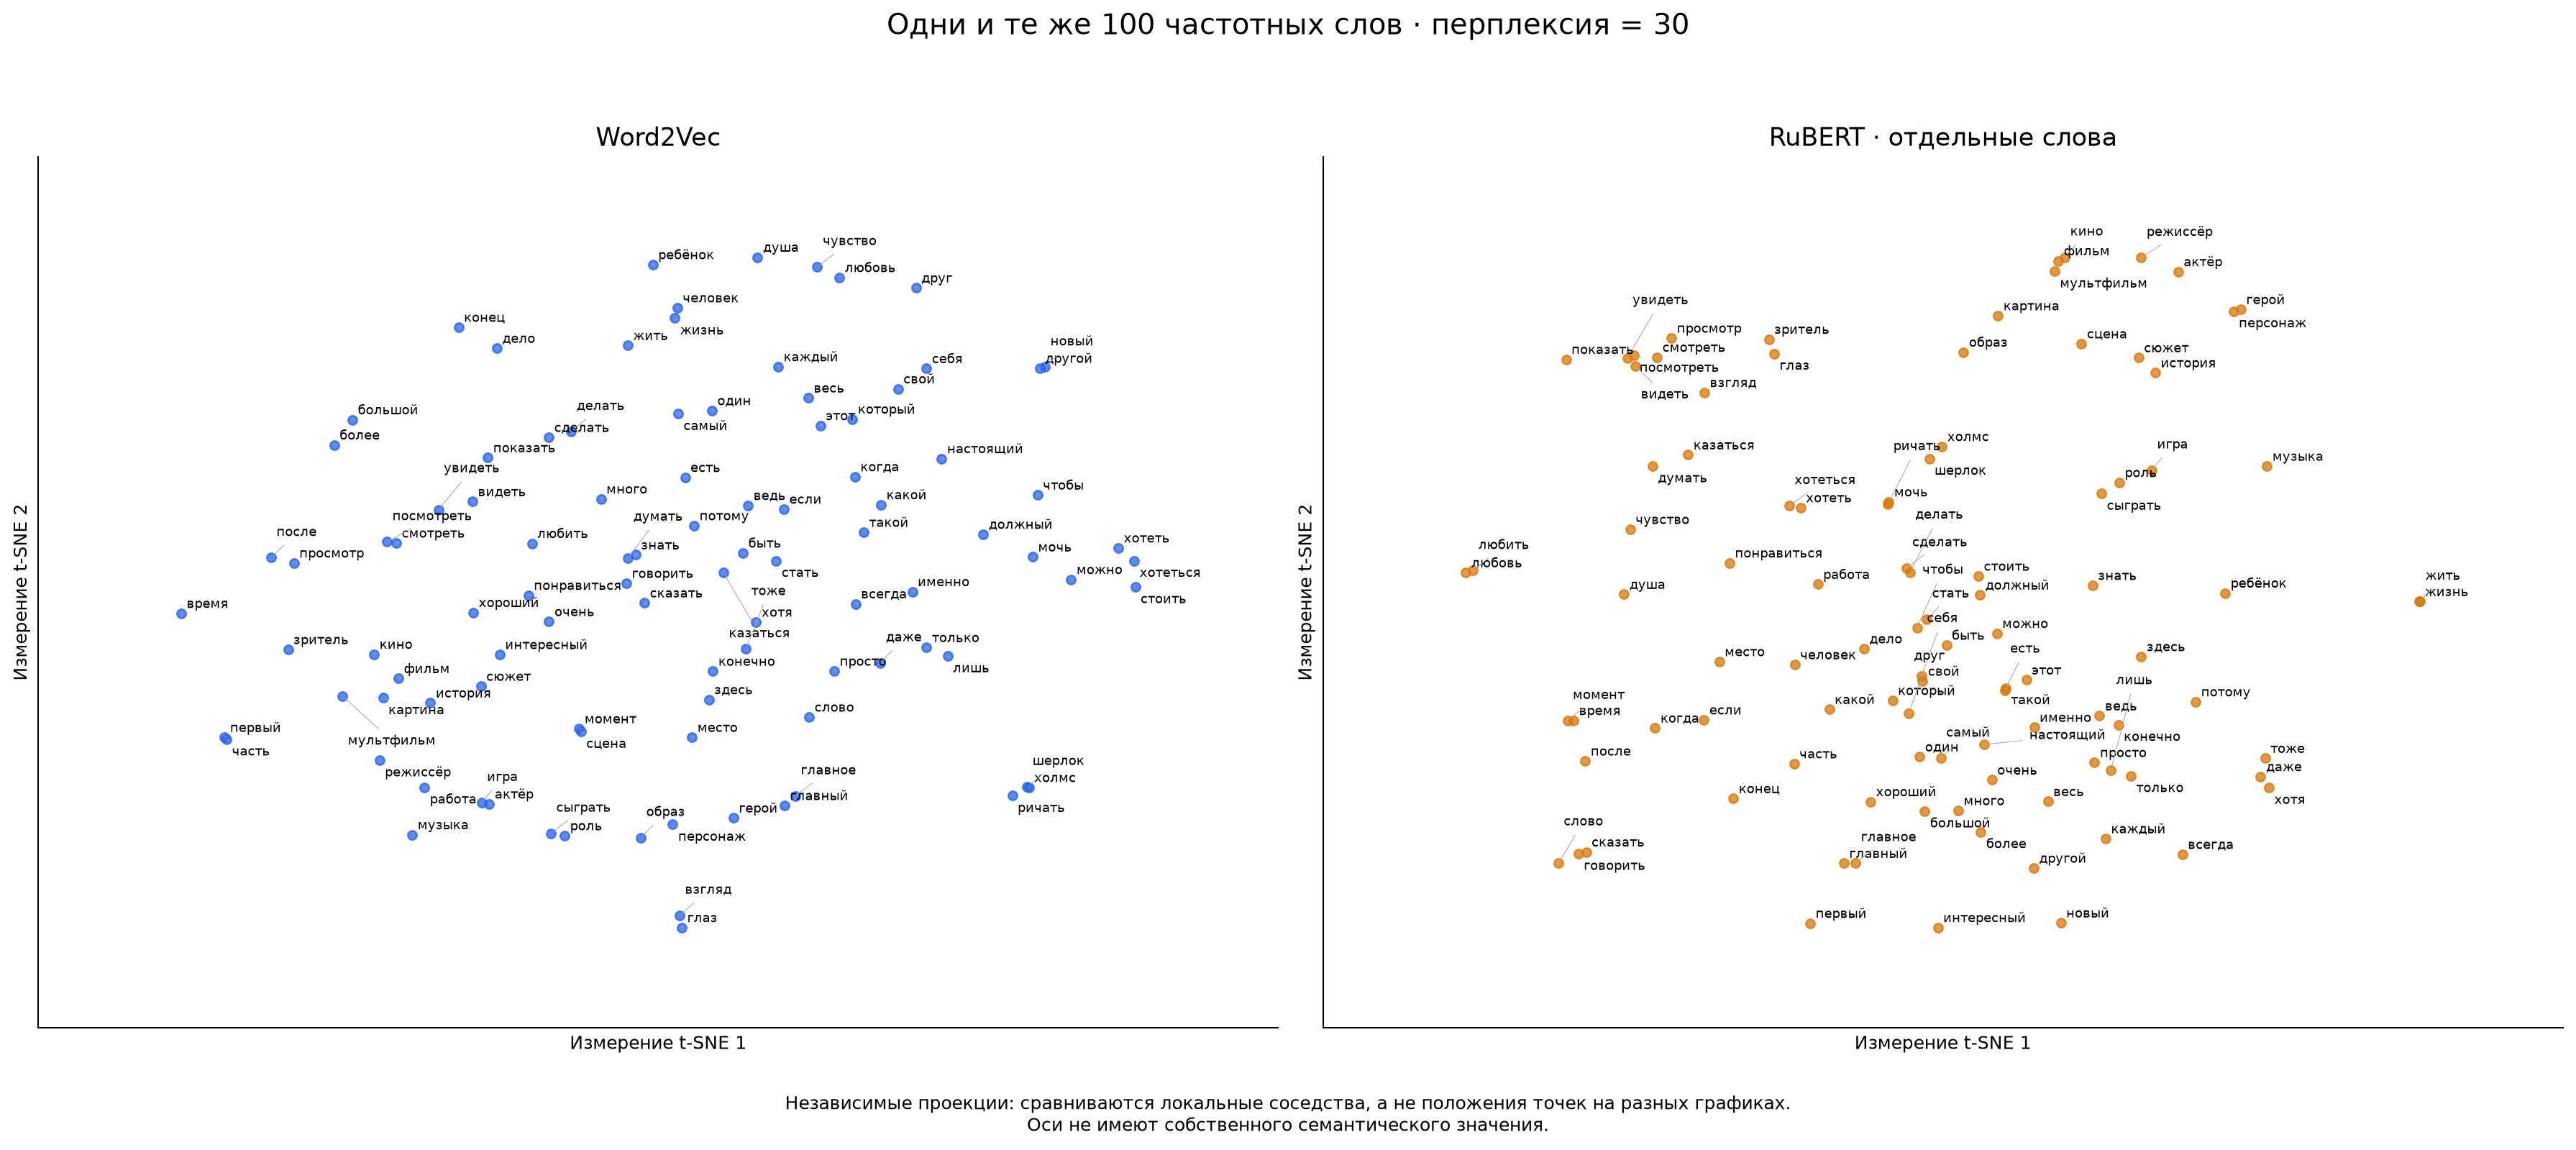

In [22]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.preprocessing import normalize

n = len(palabras)
if n < 2:
    raise ValueError("Для сравнения необходимы как минимум два слова.")
if len(vectores_w2v) != n or len(vectores_rubert) != n:
    raise ValueError("Матрицы должны содержать по одной строке на слово, в одинаковом порядке.")

# Значение perplexity должно быть меньше числа точек.
perplexity = min(30.0, (n - 1) / 3)

def proyectar_tsne(vectores):
    """Проецирует матрицу эмбеддингов на двумерное пространство."""
    vectores = normalize(np.asarray(vectores), norm="l2")
    return TSNE(
        n_components=2,
        perplexity=perplexity,
        metric="cosine",
        init="pca",
        learning_rate="auto",
        max_iter=1_000,
        random_state=42
    ).fit_transform(vectores)

posiciones_w2v = proyectar_tsne(vectores_w2v)
posiciones_rubert = proyectar_tsne(vectores_rubert)

fig, axes = plt.subplots(1, 2, figsize=(20, 9))
for ax, posiciones, titulo, color in [
    (axes[0], posiciones_w2v, "Word2Vec", "#2563eb"),
    (axes[1], posiciones_rubert, "RuBERT · отдельные слова", "#d97706")
]:
    ax.scatter(posiciones[:, 0], posiciones[:, 1], s=25, color=color, alpha=0.75)
    for palabra, (x, y) in zip(palabras, posiciones):
        ax.annotate(palabra, (x, y), xytext=(3, 3),
                    textcoords="offset points", fontsize=7,
                    arrowprops={"arrowstyle": "-", "color": "0.65", "lw": 0.4})
    ax.set_title(titulo, fontsize=14)
    ax.set_xlabel("Измерение t-SNE 1")
    ax.set_ylabel("Измерение t-SNE 2")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.margins(0.15)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(f"Одни и те же {n} частотных слов · перплексия = {perplexity:g}", fontsize=16)
fig.text(0.5, 0.02,
         "Независимые проекции: сравниваются локальные соседства, а не положения точек на разных графиках.\n"
         "Оси не имеют собственного семантического значения.",
         ha="center", fontsize=10)
fig.tight_layout(rect=(0, 0.07, 1, 0.94))
# Для уменьшения наложений смещаем только подписи; точки остаются на месте.
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
for ax in axes:
    ocupados = []
    for etiqueta in ax.texts:
        for dx in (3, -35, 25):
            libre = False
            for dy in (3, 12, -9, 21, -18, 30, -27, 39, -36, 48, -45):
                etiqueta.set_position((dx, dy))
                caja = plt.Text.get_window_extent(etiqueta, renderer).expanded(1.05, 1.15)
                if not any(caja.overlaps(otra) for otra in ocupados):
                    libre = True
                    break
            if libre:
                break
        ocupados.append(caja)
Path("resultados").mkdir(exist_ok=True)
fig.savefig("resultados/tsne_comparacion.png", dpi=180, bbox_inches="tight")
plt.close(fig)
from base64 import b64encode
from IPython.display import display
display({
    "image/png": b64encode(Path("resultados/tsne_comparacion.png").read_bytes()).decode("ascii"),
    "text/plain": "Графики t-SNE: Word2Vec и RuBERT."
}, raw=True)


## Итоговые выводы и интерпретация графиков

На графиках видны явные различия между двумя моделями. Например, слова «время» и «момент» в случае RuBERT находятся рядом, а в случае Word2Vec — на расстоянии друг от друга. Однако наблюдаются и сходства: например, «большой» / «более» или «посмотреть» / «смотреть» / «увидеть» / «показать» в обоих случаях расположены примерно на одинаковом расстоянии и образуют группы.

Это может быть связано с тем, что некоторые слова легко используются в разных контекстах. Например, «персонаж» и «герой» — слова, которые обычно употребляются в одном контексте. В то же время «первый» и «момент» могут встречаться как вместе, так и по отдельности, причём слово «первый» используется в большем числе различных контекстов.
